In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

In [ ]:
import pandas as pd
import os

file_path = "Online Retail.xlsx"

# Load the dataset
if os.path.exists(file_path):
    print("Loading Excel file...")
    df = pd.read_excel(file_path)
    print("Initial shape:", df.shape)
    print(df.info())
else:
    print("File not found.")

Loading Excel file...
Initial shape: (541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
None


In [ ]:
# Clean dataset
df = df.dropna(subset=['CustomerID'])
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
df['CustomerID'] = df['CustomerID'].astype(int)
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print("Cleaned shape:", df.shape)
print(df.head())

Cleaned shape: (397884, 9)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  TotalAmount  
0 2010-12-01 08:26:00       2.55       17850  United Kingdom        15.30  
1 2010-12-01 08:26:00       3.39       17850  United Kingdom        20.34  
2 2010-12-01 08:26:00       2.75       17850  United Kingdom        22.00  
3 2010-12-01 08:26:00       3.39       17850  United Kingdom        20.34  
4 2010-12-01 08:26:00       3.39       17850  United Kingdom        20.34  


In [ ]:
# Calculate RFM Metrics
import datetime as dt

# Reference date for recency calculation
ref_date = df['InvoiceDate'].max() + dt.timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (ref_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
}).rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalAmount': 'Monetary'
})

print("RFM dataframe preview:")
display(rfm.head())

RFM dataframe preview:


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


PCA Explained Variance Ratio: [0.75102042 0.18759201]


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


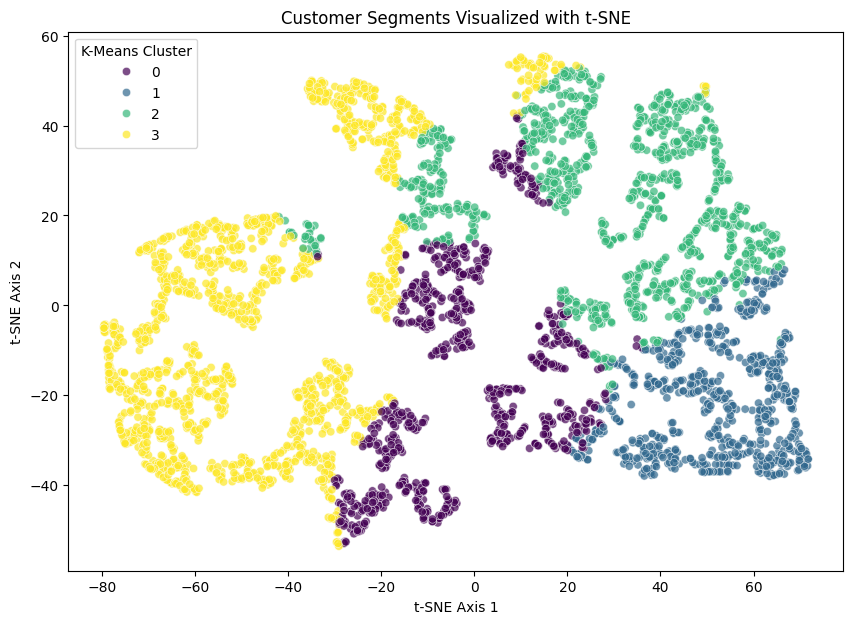

,Recency,Frequency,Monetary,Outliers_Count
KMeans_Cluster,,,,
0,18.124253,2.148148,551.819534,11
1,12.131285,13.713687,8074.266872,58
2,71.084399,4.083546,1802.829005,20
3,182.496898,1.318238,343.450032,16


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# 1. Handle skewness with log transformation and scale the RFM data
rfm_log = np.log1p(rfm)
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# 2. Reduce dimensions with PCA
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)
print(f"PCA Explained Variance Ratio: {pca.explained_variance_ratio_}")

# 3. Apply K-Means and DBSCAN Clustering
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['KMeans_Cluster'] = kmeans.fit_predict(rfm_scaled)

dbscan = DBSCAN(eps=0.5, min_samples=15)
rfm['DBSCAN_Cluster'] = dbscan.fit_predict(rfm_scaled)

# 4. Visualize segments using t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_iter=1000)
rfm_tsne = tsne.fit_transform(rfm_scaled)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=rfm_tsne[:, 0], y=rfm_tsne[:, 1],
    hue=rfm['KMeans_Cluster'],
    palette='viridis', alpha=0.7
)
plt.title('Customer Segments Visualized with t-SNE')
plt.xlabel('t-SNE Axis 1')
plt.ylabel('t-SNE Axis 2')
plt.legend(title='K-Means Cluster')
plt.show()

# 5. Analyze and display actionable marketing personas
personas = rfm.groupby('KMeans_Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'DBSCAN_Cluster': lambda x: (x == -1).sum() # Count outlier points per cluster
}).rename(columns={'DBSCAN_Cluster': 'Outliers_Count'})

display(personas)